In [25]:
import pandas as pd
import requests

In [37]:
with open("../.config/av") as f:
    API_KEY = f.readline().strip()

BASE_URL = "https://www.alphavantage.co/query"

user_input_stock_symbol = input("Enter stock symbol: ")

params = {
    "function": "TIME_SERIES_DAILY",
    "symbol":  str(user_input_stock_symbol).upper().strip(),
    "apikey": str(API_KEY)
}

response = requests.get(BASE_URL, params=params)
data = response.json()
print(data)


{'Meta Data': {'1. Information': 'Daily Prices (open, high, low, close) and Volumes', '2. Symbol': 'NVDA', '3. Last Refreshed': '2026-11-18', '4. Output Size': 'Compact', '5. Time Zone': 'US/Eastern'}, 'Time Series (Daily)': {'2026-11-18': {'1. open': '159.1900', '2. high': '159.7000', '3. low': '150.4000', '4. close': '150.9600', '5. volume': '340338858'}, '2026-11-17': {'1. open': '156.8950', '2. high': '158.1900', '3. low': '150.3301', '4. close': '155.4600', '5. volume': '406985086'}, '2026-11-16': {'1. open': '159.0150', '2. high': '163.2000', '3. low': '155.0100', '4. close': '156.1400', '5. volume': '333822062'}, '2026-11-13': {'1. open': '169.9050', '2. high': '170.0000', '3. low': '158.3900', '4. close': '162.8500', '5. volume': '365796552'}, '2026-11-12': {'1. open': '151.0050', '2. high': '167.1400', '3. low': '148.8000', '4. close': '166.1900', '5. volume': '747707648'}, '2026-11-11': {'1. open': '172.8000', '2. high': '177.5400', '3. low': '170.7700', '4. close': '173.7300

In [38]:
api_symbol = data['Meta Data']['2. Symbol']

time_series = data.get('Time Series (Daily)', {})
df = pd.DataFrame.from_dict(time_series, orient='index')
df = df.rename(columns={
    "1. open": "open",
    "2. high": "high",
    "3. low": "low",
    "4. close": "close",
    "5. volume": "volume"
})
df = df.astype(float)

price_cols = ["open", "high", "low", "close"]
df[price_cols] = df[price_cols].round(2)
df.index = pd.to_datetime(df.index)
df = df.sort_index(ascending=False)
df.insert(0, "symbol", api_symbol.upper())

print("symbol: ", api_symbol.upper())
print(df.head())

symbol:  NVDA
           symbol    open    high     low   close       volume
2026-11-18   NVDA  159.19  159.70  150.40  150.96  340338858.0
2026-11-17   NVDA  156.90  158.19  150.33  155.46  406985086.0
2026-11-16   NVDA  159.01  163.20  155.01  156.14  333822062.0
2026-11-13   NVDA  169.90  170.00  158.39  162.85  365796552.0
2026-11-12   NVDA  151.00  167.14  148.80  166.19  747707648.0


In [39]:
import matplotlib.pyplot as plt
import mplcursors

NVDA


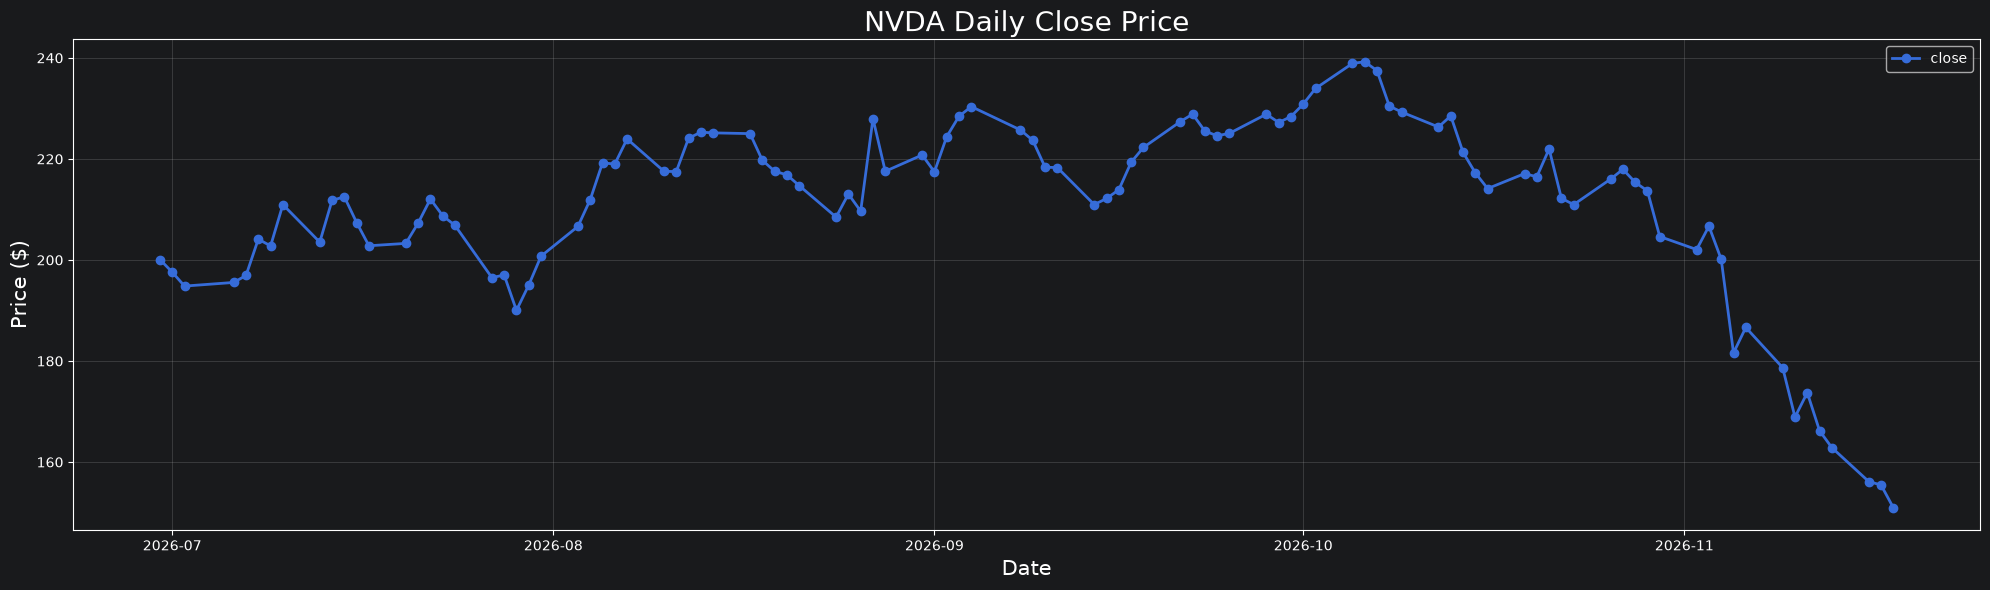

In [40]:
plt.figure(figsize=(20, 6))
plt.plot(df["close"],marker="o", linewidth=2, label="close")
plt.title(f"{df["symbol"].iloc[0]} Daily Close Price", fontsize=20)
plt.hspace=0.9
plt.xlabel("Date", fontsize=15)
plt.ylabel("Price ($)", fontsize=15)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

print(df["symbol"].iloc[0])



plt.show()

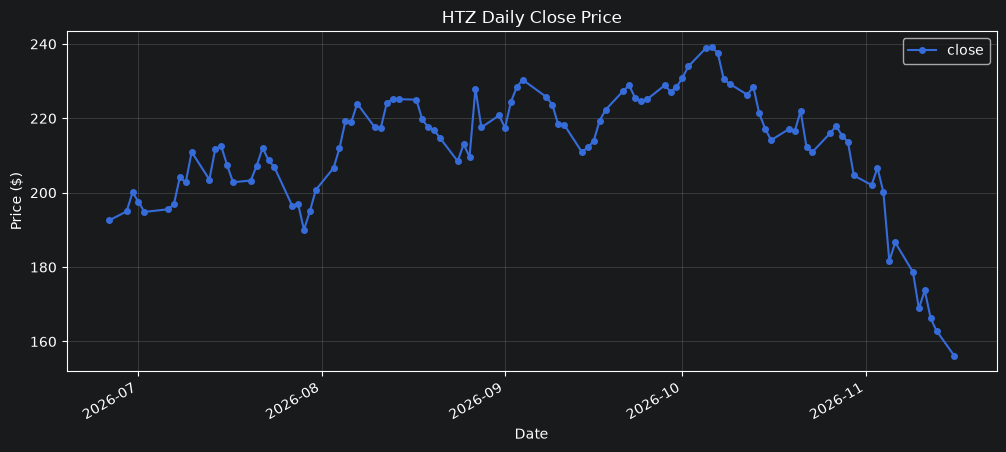

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mplcursors

fig, ax = plt.subplots(figsize=(12, 5))

# Capture the line so we can attach the cursor to it
line, = ax.plot(df.index, df["close"], marker="o", markersize=4, label="close")

ax.set_title("HTZ Daily Close Price")
ax.set_xlabel("Date")
ax.set_ylabel("Price ($)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()

# Attach cursor to the line (not the axes)
cursor = mplcursors.cursor(line, hover=True)

@cursor.connect("add")
def on_add(sel):
    # Convert matplotlib date number → real datetime
    #date = mdates.num2date(sel.target[0]).strftime("%Y-%m-%d")
    price = sel.target[1]
    sel.annotation.set_text(f"Close: ${price:.2f}")

plt.show()

In [42]:
print(df.index.min(), df.index.max())   # what dates do you actually have?
print(df[["open", "close"]].describe()) # what are the real price ranges?
print(df.tail(10))                      # see the most recent rows

2026-06-30 00:00:00 2026-11-18 00:00:00
             open       close
count  100.000000  100.000000
mean   211.732900  211.053800
std     18.223164   18.212311
min    151.000000  150.960000
25%    205.465000  203.467500
50%    216.270000  215.050000
75%    223.055000  224.170000
max    242.100000  239.240000
           symbol    open    high     low   close       volume
2026-07-14   NVDA  208.20  212.55  203.80  211.80  124379646.0
2026-07-13   NVDA  208.54  210.57  203.00  203.53  121411018.0
2026-07-10   NVDA  202.00  211.00  201.92  210.96  148421001.0
2026-07-09   NVDA  204.46  204.58  198.96  202.78  132037359.0
2026-07-08   NVDA  195.18  205.16  195.06  204.12  147419133.0
2026-07-07   NVDA  192.37  198.41  191.14  196.93  124154574.0
2026-07-06   NVDA  194.42  197.55  193.99  195.55  108999015.0
2026-07-02   NVDA  197.14  200.06  192.35  194.83  142385548.0
2026-07-01   NVDA  196.20  199.85  193.45  197.58  146147597.0
2026-06-30   NVDA  197.24  200.63  195.11  200.09  166476665

In [41]:
import plotly.graph_objects as go
import nbformat

fig = go.Figure()

fig.add_trace(go.Scatter(
    x = df.index,
    y = df["close"],
    mode = "lines+markers",
    name = "close",
    hovertemplate=(
        "Date: %{x|%m-%d-%Y}<br>"
        "Close: $%{y:.2f}<extra></extra>"
    )
))

fig.add_trace(go.Scatter(
    x = df.index,
    y = df["open"],
    mode = "lines+markers",
    name = "open",
    hovertemplate=(
    "Date: %{x|%m-%d-%Y}<br>"
    "Open: $%{y:.2f}<extra></extra>"
    )
))

fig.update_layout(
    showlegend = True,
    legend=dict(
    #title=dict(text='Legend'),
    font=dict(size=12, color='white'),
    orientation="h",                # horizontal
    yanchor="bottom",
    y=1.02,
    xanchor="right",
    x=1
),
    title= f"{df['symbol'].iloc[0]} Daily Open & Close Price",
    xaxis_title="Date",
    yaxis_title="Price ($)",
    template="plotly_dark",
    hovermode="closest"
)

# Add the timeline buttons
fig.update_xaxes(
    rangeselector=dict(
        buttons=list([
            dict(count=5, label="5D", step="day", stepmode="backward"),
            dict(count=1, label="1M", step="month", stepmode="backward"),
            dict(count=6, label="6M", step="month", stepmode="backward"),
            dict(step="all", label="All")
        ]),
        bgcolor="rgba(50,50,50,0.7)",
        activecolor="rgba(100,100,100,0.8)",
        font=dict(color="white")
    )
)

fig.show()